In [3]:
from src.preprocessing import clean_data, load_data,split_data, build_preprocessor

clean_data()
df = load_data()
print(len(df[df["Social_Media_Hours"] > df["Screen_Time_Hours"]]))

Rows fixed: 37
0


In [4]:
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
preprocessor = build_preprocessor()
print(X_train.shape, X_test.shape)

(1600, 15) (400, 15)


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

In [6]:
models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

results = {}
for name , model in models.items():
    pip = Pipeline(
        steps=[
            ("preprocessor",preprocessor),
            ("model",model)
        ]
    )
    
    scores = cross_val_score(pip,X_train, y_train,cv=cv,scoring="f1_macro")
    results[name] = scores
    print(name)
    print("Mean F1 macro:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))
    print("-" * 40)

Logistic Regression
Mean F1 macro: 0.7511
Std: 0.022
----------------------------------------
Random Forest
Mean F1 macro: 0.6792
Std: 0.0287
----------------------------------------
Gradient Boosting
Mean F1 macro: 0.6859
Std: 0.0227
----------------------------------------


In [7]:
import pandas as pd
results_df = pd.DataFrame(results)
print(results_df.round(4))

   Logistic Regression  Random Forest  Gradient Boosting
0               0.7470         0.7119             0.7208
1               0.7304         0.6387             0.6672
2               0.7340         0.6905             0.6785
3               0.7517         0.7028             0.7030
4               0.7922         0.6521             0.6600


In [8]:
summary = pd.DataFrame({
    "mean": results_df.mean(),
    "std": results_df.std()
})
print(summary.round(4))

                       mean     std
Logistic Regression  0.7511  0.0246
Random Forest        0.6792  0.0321
Gradient Boosting    0.6859  0.0254


In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix,classification_report,f1_score
import matplotlib.pyplot as plt
import seaborn as sns 

In [16]:
labels = ["Low", "Medium", "High"]
best_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

y_pred = cross_val_predict(best_pipe, X_train, y_train, cv=cv)

In [17]:
print(classification_report(y_train, y_pred, labels=labels))

              precision    recall  f1-score   support

         Low       0.81      0.81      0.81       528
      Medium       0.63      0.63      0.63       528
        High       0.81      0.81      0.81       544

    accuracy                           0.75      1600
   macro avg       0.75      0.75      0.75      1600
weighted avg       0.75      0.75      0.75      1600



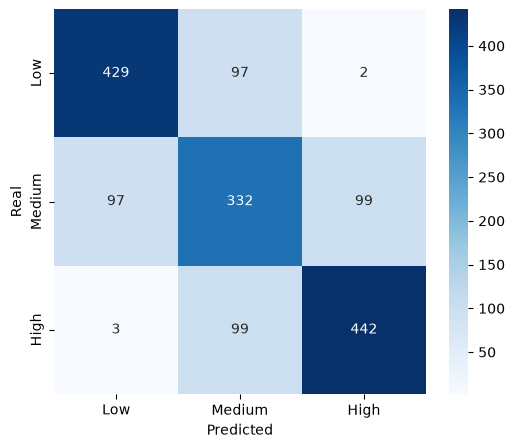

In [24]:
cm = confusion_matrix(y_train, y_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

In [25]:
rf_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])
rf_pipe.fit(X_train, y_train)
train_pred = rf_pipe.predict(X_train)
train_score = f1_score(y_train, train_pred, average="macro")
print("Random Forest train F1 macro:", round(train_score, 4))
print("Random Forest CV F1 macro: 0.6792")

Random Forest train F1 macro: 1.0
Random Forest CV F1 macro: 0.6792


In [31]:
from sklearn.model_selection import GridSearchCV

pram_grid_logistic = {
    'model__C' : [0.01, 0.1, 1, 10, 100,1000]
}

model_logistic = LogisticRegression()

logistic_pip = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ('model',model_logistic)
    ]
)

GridSearchCV_logistic = GridSearchCV(
    estimator=logistic_pip,
    param_grid=pram_grid_logistic,
    cv=cv,
    scoring='f1_macro'
)

GridSearchCV_logistic.fit(X_train,y_train)

print("best param: ",GridSearchCV_logistic.best_params_)
print("best score: ",GridSearchCV_logistic.best_score_)

best param:  {'model__C': 100}
best score:  0.7511685884882555


In [32]:
cv_table = pd.DataFrame(GridSearchCV_logistic.cv_results_)
print(cv_table[["param_model__C", "mean_test_score", "std_test_score"]])

   param_model__C  mean_test_score  std_test_score
0            0.01         0.701505        0.020533
1            0.10         0.747405        0.014206
2            1.00         0.751053        0.022030
3           10.00         0.750035        0.020407
4          100.00         0.751169        0.021233
5         1000.00         0.751169        0.021233


In [33]:
rf_grid = {
    "model__max_depth":[3,5,8 ,None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__max_features": ["sqrt", 0.5]
}
rf_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_search = GridSearchCV(
    rf_pipe,
    rf_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)
rf_search.fit(X_train, y_train)

print("RF best params:", rf_search.best_params_)
print("RF best score:", rf_search.best_score_)

RF best params: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}
RF best score: 0.679176877174729


In [34]:
gb_grid = {
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__n_estimators": [100, 200, 300]
}

gb_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb_search = GridSearchCV(
    gb_pipe, 
    gb_grid, 
    cv=cv, 
    scoring="f1_macro", 
    n_jobs=-1
)
gb_search.fit(X_train, y_train)

print("GB best params:", gb_search.best_params_)
print("GB best score:", gb_search.best_score_)

GB best params: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300}
GB best score: 0.6913159942165671


In [35]:
comparison = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "cv_f1_macro": [GridSearchCV_logistic.best_score_,
                    rf_search.best_score_,
                    gb_search.best_score_]
})
print(comparison.round(4))

                 model  cv_f1_macro
0  Logistic Regression       0.7512
1        Random Forest       0.6792
2    Gradient Boosting       0.6913


              precision    recall  f1-score   support

         Low       0.83      0.80      0.82       132
      Medium       0.64      0.64      0.64       132
        High       0.81      0.83      0.82       136

    accuracy                           0.76       400
   macro avg       0.76      0.76      0.76       400
weighted avg       0.76      0.76      0.76       400



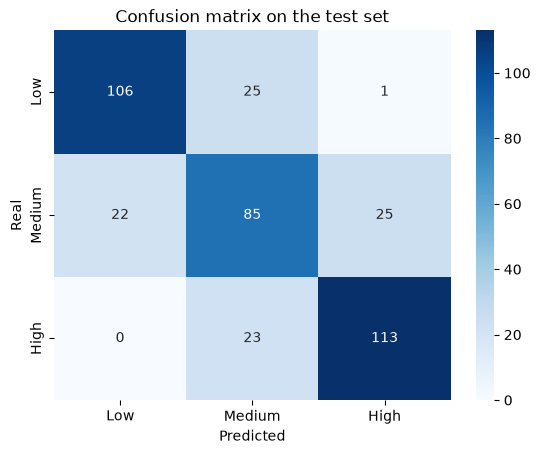

In [36]:
from sklearn.metrics import classification_report, confusion_matrix

best_search = GridSearchCV_logistic
best_model = best_search.best_estimator_

y_test_pred = best_model.predict(X_test)

print(classification_report(y_test, y_test_pred, labels=labels))

cm = confusion_matrix(y_test, y_test_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.title("Confusion matrix on the test set")
plt.show()

In [39]:
print(cm)

[[106  25   1]
 [ 22  85  25]
 [  0  23 113]]


In [37]:
import joblib

joblib.dump(best_model, "../models/psychesense_pipeline.joblib")

['../models/psychesense_pipeline.joblib']